In [1]:
import tensorflow as tf
import numpy as np
import random

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

In [2]:
index = 'vabc' # 'tgi', 'vabc', or 'ngrdi'
augmented = True # 'true/false'
model = 'vgg'
norm = 'zs'

In [3]:
import os

idx = 0

bm_name = f"best_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}.h5" # best model name 

while os.path.exists(bm_name) == True:
    bm_name = f"best_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}_{idx}.h5" # best model name 
    idx += 1

idx = 0

lm_name = f"last_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}.h5" # last model name

while os.path.exists(lm_name) == True:
    lm_name = f"last_{norm}{'_augmented' if augmented == True else ''}_{index}_{model}_{idx}.h5" # last model name
    idx += 1

In [4]:
print(bm_name)

best_zs_augmented_vabc_vgg.h5


In [5]:
# import dataset

import cv2 as cv
import os

x_train = []
y_train = []

train_path = 'train' if augmented == False else 'undersampled_augmented'

print(train_path)

for classes in os.listdir(train_path):
    class_path = os.path.join(train_path, classes)
    for image_name in os.listdir(class_path):
        img = cv.imread(os.path.join(class_path, image_name))
        x_train.append(img)
        y_train.append(classes)

undersampled_augmented


In [6]:
x_val = []
y_val = []

val_path = 'val'

for classes in os.listdir(val_path):
    class_path = os.path.join(val_path, classes)
    for image_name in os.listdir(class_path):
        img = cv.imread(os.path.join(class_path, image_name))
        x_val.append(img)
        y_val.append(classes)

In [7]:
x_test = []
y_test = []

test_path = 'test'

for classes in os.listdir(test_path):
    class_path = os.path.join(test_path, classes)
    for image_name in os.listdir(class_path):
        img = cv.imread(os.path.join(class_path, image_name))
        x_test.append(img)
        y_test.append(classes)

In [8]:
import func

y_train = func.Preprocessing.convert_to_numeric(y_train)
y_val = func.Preprocessing.convert_to_numeric(y_val)
y_test = func.Preprocessing.convert_to_numeric(y_test)

In [9]:
train_index = []

for x in x_train:
    x_temp = func.Preprocessing.convert_to_indices(x, index)
    x_temp = func.Preprocessing.global_z_score_normalization(x_temp, index)
    train_index.append(x_temp)

del x_train

val_index = []

for x in x_val:
    x_temp = func.Preprocessing.convert_to_indices(x, index)
    x_temp = func.Preprocessing.global_z_score_normalization(x_temp, index)
    val_index.append(x_temp)

del x_val

test_index = []

for x in x_test:
    x_temp = func.Preprocessing.convert_to_indices(x, index)
    x_temp = func.Preprocessing.global_z_score_normalization(x_temp, index)
    test_index.append(x_temp)

del x_test

In [10]:
import tensorflow as tf
from tensorflow.keras.utils import to_categorical

train_index = tf.convert_to_tensor(train_index, dtype=tf.float32)
y_train = tf.convert_to_tensor(y_train, dtype=tf.float32)
val_index = tf.convert_to_tensor(val_index, dtype=tf.float32)
y_val = tf.convert_to_tensor(y_val, dtype=tf.float32)
test_index = tf.convert_to_tensor(test_index, dtype=tf.float32)
y_test = tf.convert_to_tensor(y_test, dtype=tf.float32)

y_train = to_categorical(y_train, num_classes=10)
y_val = to_categorical(y_val, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

In [11]:
# VGG Modified

from tensorflow.keras.layers import Input, Conv2D, MaxPool2D, Flatten, Dense, BatchNormalization, GlobalAvgPool2D, Dropout
from tensorflow.keras import Model

input_tensor = Input(shape = (256, 256, 1), name="Input_Layer")

# Block 1
x = Conv2D(16, (3, 3), activation="relu", padding="same", name="Conv1-1")(input_tensor)
x = BatchNormalization()(x)
x = MaxPool2D((2, 2), strides=(2, 2), name="Maxpool1")(x)

# Block 2
x = Conv2D(16, (3, 3), activation="relu", padding="same", name="Conv2-1")(x)
x = BatchNormalization()(x)
x = MaxPool2D((2, 2), strides=(2, 2), name="Maxpool2")(x)

# Block 3
x = Conv2D(32, (3, 3), activation="relu", padding="same", name="Conv3-1")(x)
x = BatchNormalization()(x)
x = Conv2D(32, (3, 3), activation="relu", padding="same", name="Conv3-2")(x)
x = BatchNormalization()(x)
x = MaxPool2D((2, 2), strides=(2, 2), name="Maxpool3")(x)

# Block 4
x = Conv2D(64, (3, 3), activation="relu", padding="same", name="Conv4-1")(x)
x = BatchNormalization()(x)
x = Conv2D(64, (3, 3), activation="relu", padding="same", name="Conv4-2")(x)
x = BatchNormalization()(x)
x = MaxPool2D((2, 2), strides=(2, 2), name="Maxpool4")(x)

# Classification Block
x = GlobalAvgPool2D(name="GlobalAvgPool")(x)
# x = Flatten(name="flatten")(x)
x = Dense(64, activation="relu", name="FC-1")(x)
x = Dropout(0.5)(x)
x = Dense(10, activation="softmax", name="FC-2")(x)

vggmod_model = Model(input_tensor, x, name="vgg16_bn")

In [12]:
vggmod_model.summary()

Model: "vgg16_bn"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 Input_Layer (InputLayer)    [(None, 256, 256, 1)]     0         
                                                                 
 Conv1-1 (Conv2D)            (None, 256, 256, 16)      160       
                                                                 
 batch_normalization (BatchN  (None, 256, 256, 16)     64        
 ormalization)                                                   
                                                                 
 Maxpool1 (MaxPooling2D)     (None, 128, 128, 16)      0         
                                                                 
 Conv2-1 (Conv2D)            (None, 128, 128, 16)      2320      
                                                                 
 batch_normalization_1 (Batc  (None, 128, 128, 16)     64        
 hNormalization)                                          

In [13]:
import tensorflow as tf

vggmod_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss=tf.keras.losses.CategoricalCrossentropy(), metrics=[tf.keras.metrics.CategoricalAccuracy(), tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])

In [14]:
batch_size = 16

# acc_callback = tf.keras.callbacks.EarlyStopping(monitor="val_binary_accuracy", patience=20, mode="max", verbose=1)
# loss_callback = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, mode="min", verbose=1)
checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath=bm_name, monitor="val_categorical_accuracy", mode="max", save_best_only=True, verbose=1)

with tf.device('/GPU:0'):
    vggmod_history = vggmod_model.fit(train_index, y_train, epochs=100, steps_per_epoch=len(train_index)/batch_size, verbose=1, batch_size=batch_size, validation_data=(val_index, y_val), callbacks=[checkpoint])

Epoch 1/100
1072/1071 [==============================] - ETA: 0s - loss: 1.5997 - categorical_accuracy: 0.4564 - precision: 0.7438 - recall: 0.1896
Epoch 1: val_categorical_accuracy improved from -inf to 0.67291, saving model to best_zs_augmented_vabc_vgg.h5
1071/1071 [==============================] - 30s 26ms/step - loss: 1.5997 - categorical_accuracy: 0.4564 - precision: 0.7438 - recall: 0.1896 - val_loss: 1.0644 - val_categorical_accuracy: 0.6729 - val_precision: 0.8759 - val_recall: 0.4222
Epoch 2/100
1071/1071 [============================>.] - ETA: 0s - loss: 1.2506 - categorical_accuracy: 0.5902 - precision: 0.7902 - recall: 0.3403
Epoch 2: val_categorical_accuracy improved from 0.67291 to 0.74009, saving model to best_zs_augmented_vabc_vgg.h5
1071/1071 [==============================] - 27s 25ms/step - loss: 1.2507 - categorical_accuracy: 0.5902 - precision: 0.7900 - recall: 0.3403 - val_loss: 0.8424 - val_categorical_accuracy: 0.7401 - val_precision: 0.8803 - val_recall: 0.57

In [15]:
vggmod_model.save(lm_name)

In [16]:
vggmod_train_score = vggmod_model.evaluate(test_index, y_test, batch_size=16, steps=len(test_index)/16)

170/170 [==============================] - 1s 6ms/step - loss: 0.1760 - categorical_accuracy: 0.9457 - precision: 0.9521 - recall: 0.9416


86/86 [==============================] - 1s 10ms/step


<Axes: title={'center': 'LI-VGG Confusion Matrix'}>

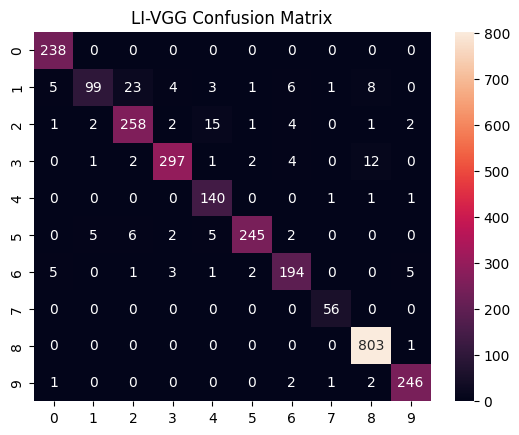

In [17]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

vggmod_pred = vggmod_model.predict(test_index)
vggmod_pred_labels = tf.argmax(vggmod_pred, axis=1)
y_test_labels = tf.argmax(y_test, axis=1)

plt.title("LI-VGG Confusion Matrix")
sns.heatmap(func.Visualization.visualize_conf_matrix(y_test, vggmod_pred), annot=True, fmt="g")

In [18]:
print(classification_report(y_test_labels, vggmod_pred_labels))

              precision    recall  f1-score   support

           0       0.95      1.00      0.98       238
           1       0.93      0.66      0.77       150
           2       0.89      0.90      0.90       286
           3       0.96      0.93      0.95       319
           4       0.85      0.98      0.91       143
           5       0.98      0.92      0.95       265
           6       0.92      0.92      0.92       211
           7       0.95      1.00      0.97        56
           8       0.97      1.00      0.98       804
           9       0.96      0.98      0.97       252

    accuracy                           0.95      2724
   macro avg       0.94      0.93      0.93      2724
weighted avg       0.95      0.95      0.94      2724



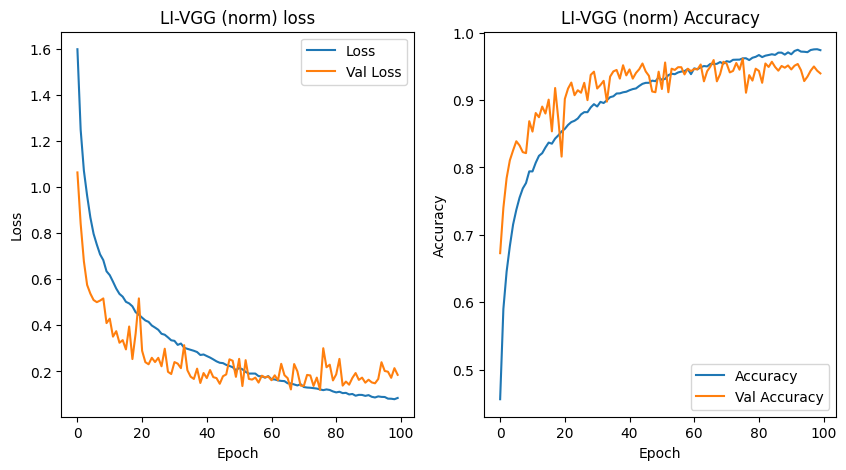

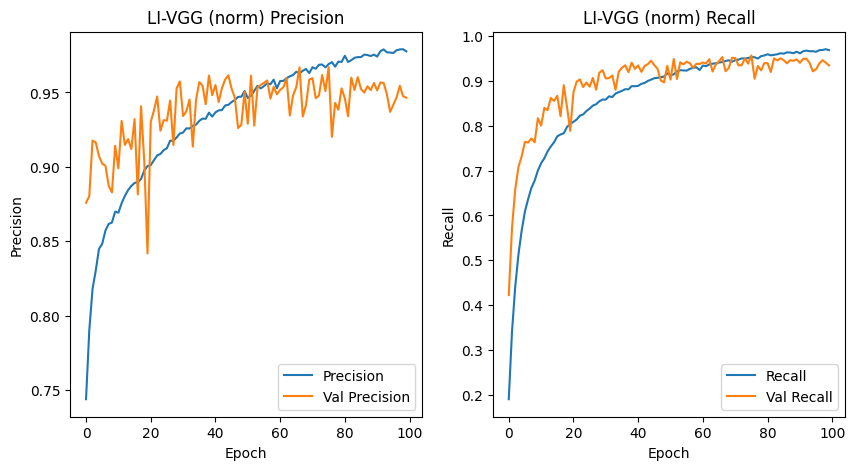

In [19]:
func.Visualization.visualize_metrics(vggmod_history, "LI-VGG (norm)")

In [20]:
best_vggmod = tf.keras.models.load_model(bm_name)

In [21]:
best_vggmod.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4), loss=tf.keras.losses.CategoricalCrossentropy(), metrics=[tf.keras.metrics.CategoricalAccuracy(), tf.keras.metrics.Precision(), tf.keras.metrics.Recall()])

In [22]:
bestvgg_score = best_vggmod.evaluate(test_index, y_test, batch_size=16, steps=len(test_index)/16)

170/170 [==============================] - 1s 6ms/step - loss: 0.1143 - categorical_accuracy: 0.9637 - precision_1: 0.9685 - recall_1: 0.9596


86/86 [==============================] - 1s 10ms/step


<Axes: title={'center': 'LI-VGG Confusion Matrix'}>

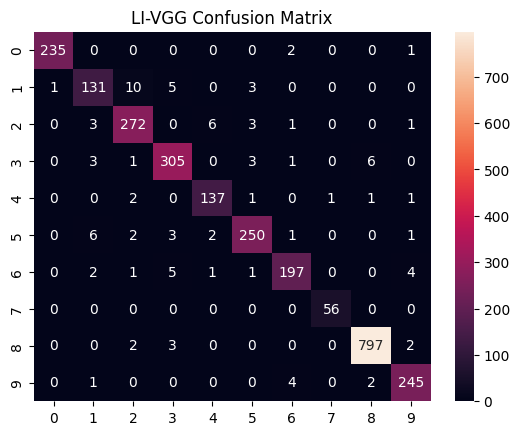

In [23]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

best_vggscore = best_vggmod.predict(test_index)
best_vggscore_labels = tf.argmax(best_vggscore, axis=1)

plt.title("LI-VGG Confusion Matrix")
sns.heatmap(func.Visualization.visualize_conf_matrix(y_test, best_vggscore), annot=True, fmt="g")

In [24]:
print(classification_report(y_test_labels, best_vggscore_labels))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       238
           1       0.90      0.87      0.89       150
           2       0.94      0.95      0.94       286
           3       0.95      0.96      0.95       319
           4       0.94      0.96      0.95       143
           5       0.96      0.94      0.95       265
           6       0.96      0.93      0.94       211
           7       0.98      1.00      0.99        56
           8       0.99      0.99      0.99       804
           9       0.96      0.97      0.97       252

    accuracy                           0.96      2724
   macro avg       0.96      0.96      0.96      2724
weighted avg       0.96      0.96      0.96      2724

